# Aula 10 — Prática · Relatório Executivo

Nesta aula: reunimos as evidências isoladas das práticas anteriores numa narrativa única de decisão. Não geramos gráficos novos — replotamos os que já existem com um viés executivo: banda de intervalo de confiança e um título que já entrega a conclusão.

## A estrutura do relatório

| Passo | Tela | Pergunta |
|---|---|---|
| 1 · Problema | Série temporal | Qual cultura sustenta vantagem ao longo do tempo? |
| 2 · Exploração | Boxplot por cultura | Os dois patamares se confirmam? |
| 3 · Avaliação | Matriz de confusão | O que o classificador entrega de fato? |
| 4 · Interpretação | Importância das variáveis | Em que o modelo se apoia? |

Cada uma das quatro telas seguintes é um passo; a conclusão executiva fecha o ciclo.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

plt.rcParams.update({
    "figure.figsize": (10, 5.6),
    "figure.dpi": 110,
    "font.size": 13,
    "axes.grid": True, "grid.alpha": 0.3,
})

AZUL, LARANJA, CINZA = "#0173B2", "#DE8F05", "#949494"

# RAIZ = a pasta uma acima da pasta deste notebook: contém base_curada.csv, environment.yml
# e as pastas aula-XX. Encontrada subindo a partir do diretório de trabalho.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base_curada.csv").is_file())
BASE = RAIZ / "base_curada.csv"
SAIDAS_A6 = Path("../aula-06/saidas")   # scores e importâncias já gerados na aula 06
SAIDAS_A10 = Path("saidas")             # relativa à pasta do notebook; criada se não existir
SAIDAS_A10.mkdir(parents=True, exist_ok=True)

def salvar(figura, nome):
    figura.savefig(SAIDAS_A10 / nome, dpi=110, bbox_inches="tight")

dados = pd.read_csv(BASE)


## 1. A série temporal

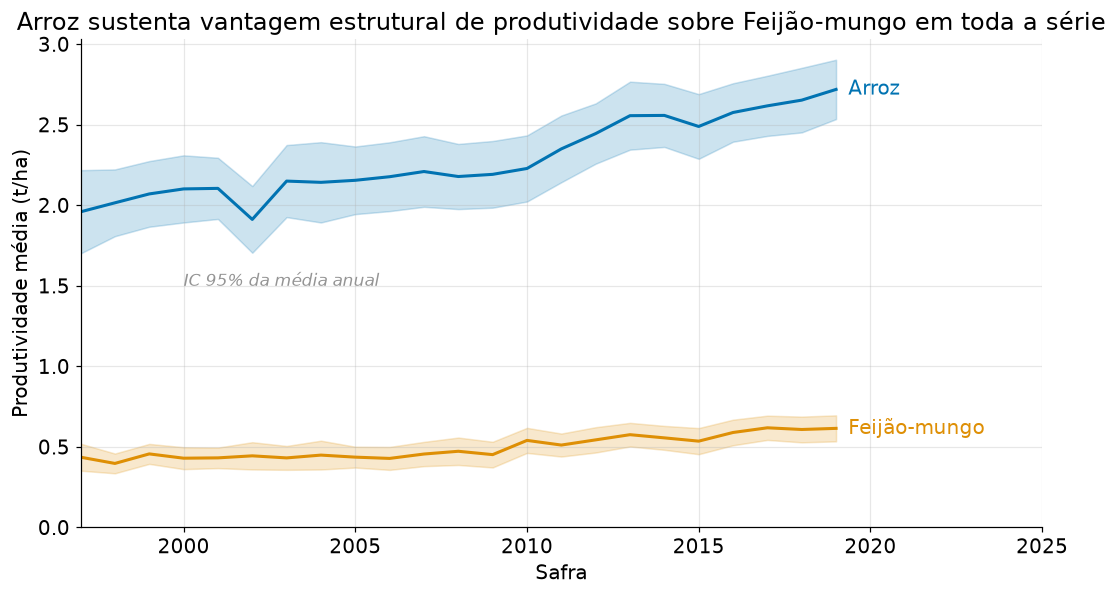

In [2]:
CULTURAS_SERIE = ["Arroz", "Feijão-mungo"]
recorte = dados[dados["cultura"].isin(CULTURAS_SERIE)]
agg = recorte.groupby(["ano", "cultura"])["produtividade_t_ha"].agg(["mean", "std", "count"]).unstack("cultura")

serie = agg["mean"]
ic = 1.96 * agg["std"] / np.sqrt(agg["count"])

fig, ax = plt.subplots()
for cultura, cor in zip(CULTURAS_SERIE, [AZUL, LARANJA]):
    ax.plot(serie.index, serie[cultura], color=cor, linewidth=2, label=cultura)
    ax.fill_between(serie.index, serie[cultura] - ic[cultura], serie[cultura] + ic[cultura], 
                    color=cor, alpha=0.2)
    ax.annotate(cultura, (serie.index[-1], serie[cultura].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", color=cor, va="center")

ax.text(2000, 1.5, "IC 95% da média anual", color=CINZA, fontsize=11, fontstyle="italic")
ax.set_xlim(serie.index.min(), serie.index.max() + 6)
ax.set_ylim(0, None)
ax.set_xlabel("Safra")
ax.set_ylabel("Produtividade média (t/ha)")
ax.set_title("Arroz sustenta vantagem estrutural de produtividade sobre Feijão-mungo em toda a série")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
salvar(fig, "f10-1-serie-temporal-banda.png")
plt.show()


## 2. O boxplot refinado

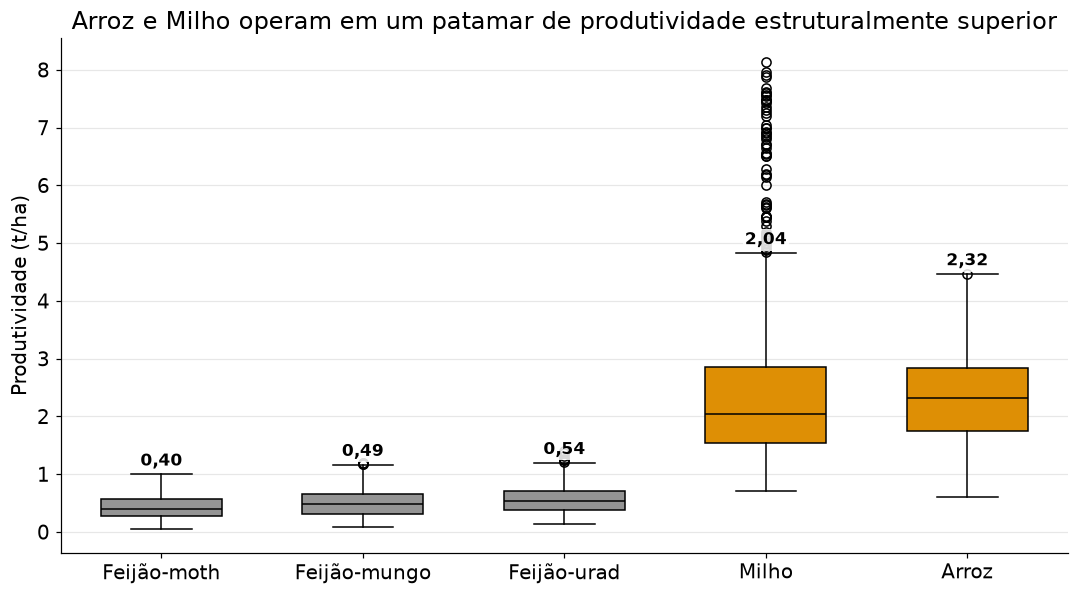

In [3]:
ALTO_PATAMAR = {"Arroz", "Milho"}
medianas = dados.groupby("cultura")["produtividade_t_ha"].median().sort_values()
ordem = medianas.index.tolist()
grupos = [dados.loc[dados["cultura"] == cultura, "produtividade_t_ha"] for cultura in ordem]
cores = [LARANJA if cultura in ALTO_PATAMAR else CINZA for cultura in ordem]

fig, ax = plt.subplots()
caixas = ax.boxplot(grupos, tick_labels=ordem, patch_artist=True, widths=0.6,
                     medianprops={"color": "black"})
for caixa, cor in zip(caixas["boxes"], cores):
    caixa.set_facecolor(cor)

tampas = caixas["caps"]
for posicao, cultura in enumerate(ordem):
    topo = tampas[2 * posicao + 1].get_ydata()[0]
    ax.text(posicao + 1, topo + 0.15, f"{medianas.loc[cultura]:.2f}".replace(".", ","),
            ha="center", fontsize=11, fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5, "alpha": 0.85})

ax.set_ylabel("Produtividade (t/ha)")
ax.set_title("Arroz e Milho operam em um patamar de produtividade estruturalmente superior")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "f10-2-boxplot-cultura-conclusao.png")
plt.show()


## 3. Matriz normalizada

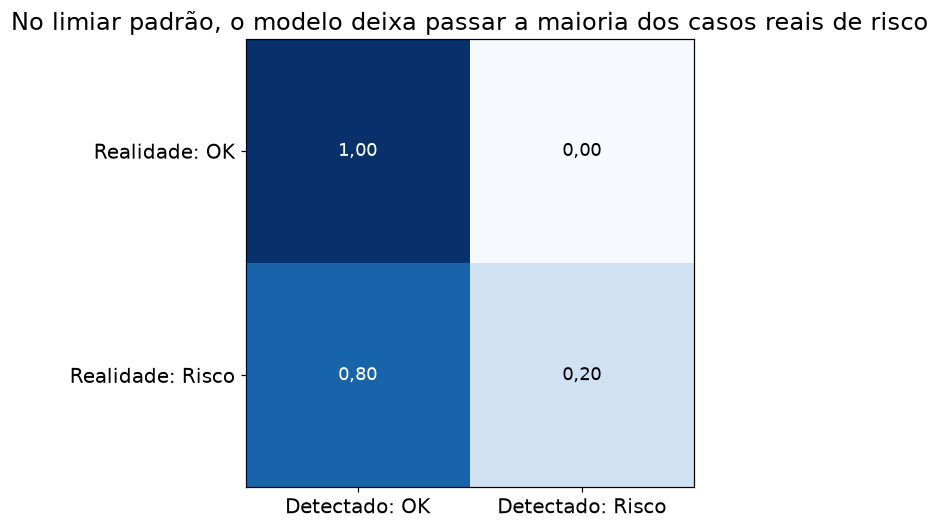

In [4]:
scores_teste = pd.read_csv(SAIDAS_A6 / "scores_teste.csv")
cm = confusion_matrix(scores_teste["real"], (scores_teste["score"] >= 0.5).astype(int))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}".replace(".", ","),
                ha="center", va="center", fontsize=12,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks([0, 1], ["Detectado: OK", "Detectado: Risco"])
ax.set_yticks([0, 1], ["Realidade: OK", "Realidade: Risco"])
ax.set_title("No limiar padrão, o modelo deixa passar a maioria dos casos reais de risco")
ax.grid(False)
fig.tight_layout()
salvar(fig, "f10-3-matriz-conclusao.png")
plt.show()


## Os dois limiares, lado a lado

In [5]:
comparacao = []
for limiar in (0.50, 0.30):
    predito = (scores_teste["score"] >= limiar).astype(int)
    real = scores_teste["real"]
    vp = int(((predito == 1) & (real == 1)).sum())
    fp = int(((predito == 1) & (real == 0)).sum())
    fn = int(((predito == 0) & (real == 1)).sum())
    vn = int(((predito == 0) & (real == 0)).sum())
    comparacao.append({
        "limiar": f"{limiar:.2f}".replace(".", ","),
        "recall (risco detectado)": f"{vp / (vp + fn):.1%}".replace(".", ","),
        "precisão (alarmes corretos)": f"{vp / (vp + fp):.1%}".replace(".", ","),
        "acurácia geral": f"{(vp + vn) / len(scores_teste):.1%}".replace(".", ","),
    })
pd.DataFrame(comparacao).set_index("limiar")

,recall (risco detectado),precisão (alarmes corretos),acurácia geral
limiar,,,
"0,50","20,2%","94,6%","78,0%"
"0,30","65,0%","52,6%","74,6%"


## 4. Feature importance refinada

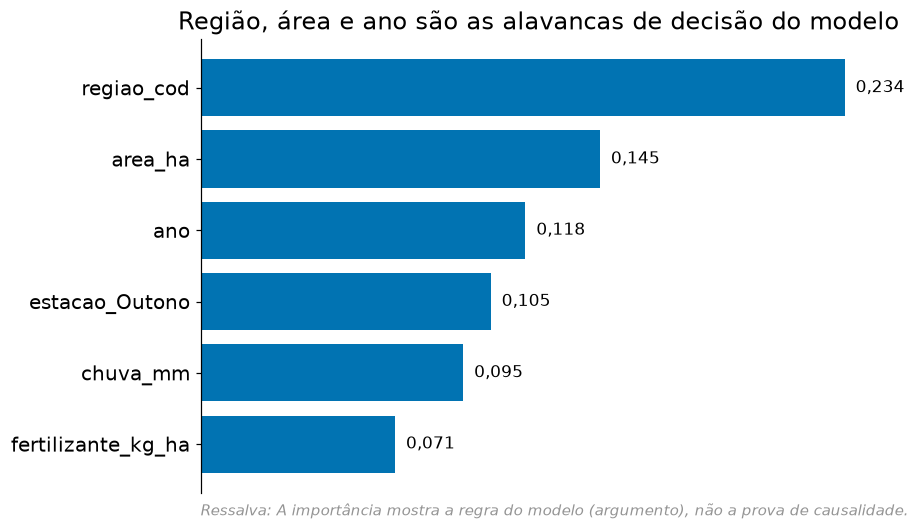

In [6]:
importancias = pd.read_csv(SAIDAS_A6 / "importancias.csv")
top6 = importancias.head(6).sort_values("importancia")

fig, ax = plt.subplots(figsize=(8.5, 5))
barras = ax.barh(top6["feature"], top6["importancia"], color=AZUL)
for barra, valor in zip(barras, top6["importancia"]):
    ax.text(valor + 0.004, barra.get_y() + barra.get_height() / 2,
            f"{valor:.3f}".replace(".", ","), va="center", fontsize=11)

ax.set_title("Região, área e ano são as alavancas de decisão do modelo")
ax.text(0, -1, "Ressalva: A importância mostra a regra do modelo (argumento), não a prova de causalidade.",
        color=CINZA, fontsize=10, fontstyle="italic")
ax.set_xticks([])
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.grid(False)
fig.tight_layout()
salvar(fig, "f10-4-importance-ressalva.png")
plt.show()


## O que levamos daqui

Conectamos o problema apontado na análise inicial — a série temporal e o boxplot — com a validação preditiva do modelo, na matriz de confusão, e com o que ela sugere para a decisão, na importância das variáveis. Sem nenhuma figura nova: só as que já tínhamos, replotadas com viés executivo, formando um mini-relatório focado em decisão.